# Implementation of TMSE-BioCRNpyler Modules: Transcription-factor-based biosensors simulation

**Installing and Initializing Modules**: See [README](https://github.com/usnistgov/TMSE_BioCRNpyler_Library/blob/main/README.md) documentation for additional details.

The following sections highlight important features of the TMSE-BioCRNpyler modules.

This notebook illustrate how to compile and simulate a transcription-factor-based biosensors, from Programming Cell-free Biosensors with DNA Strand Displacement Circuits ([Jung et al. *Nature Chemical Biology* 2022](https://www.nature.com/articles/s41589-021-00962-9)), in BioCRNpyler using the TMSE modules. The first code block implements exisiting BioCRNpyler components, mechanisms, and mixtures seemlessly with the TMSE modules to compile a chemcial reaction network (CRN). The CRN is then simulated using BioSCRAPE at various initial conditions in the second code block. 

Specific Features:
* specifying strand exchange molecules from a dictionary directly using `StrandExchangeRNA()`
* using specified strand exhange molecules to create a repressible assembly with `RepressiblePromoter()` and `DNAassembly()`

## Global variables, definitions, and dependencies

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
from pathlib import Path

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

In [2]:
# Simulate all models - example for 4 hours
timepoints = np.linspace(0,4,5001)*3600


#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (7, 7)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.02, ymax = 100):
    fs = 22
    
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.legend(title='Input',frameon=False, 
               title_fontsize = fs, fontsize=fs)

    plt.ylim(ymin,ymax)
    plt.xlim(0,4)
    plt.xticks(fontsize=fs)
    plt.yticks(fontsize=fs)
    plt.xticks(np.arange(0, 5, 1))

    # Save plot as svg
    plt.savefig(f'{figs_dir}/main_{fig_name}.svg')

# Transcription-factor-based biosensors simulation

![Transcription-factor-based biosensors](../schematics/Figure2_TFbiosensor.png)

**Transcription-factor-based Biosensors Simulation**

*Note: We use hill functions to model transcription-factor binding, while the original paper used mass acction reaction.*

In [3]:
# Define initial DNA and Reporter RNA
sim_inputs_tx = {'DNA_1': ['Input',1], 'DNA_2': ['Input',3]}, # Input DNA      
sim_inputs = {'DNA_3':['Gate',1,2],'DNA_4':['Gate',3,2], 'DNA_5':['Reporter', 2]}, # Gate DNA

# Components
step_tx = StrandExchangeMol(sim_inputs_tx, material_type= 'dna', transcription=True)
sd_dna = StrandExchangeMol(sim_inputs, material_type= 'dna')
step_tmse = TMSE([sd_dna.mol,step_tx.rna])

# Create a DNA assembly with P_repressible for both its promoter
rna_Arep, rna_Brep = step_tx.rna
# Repressors
repA = Species("repA", material_type = "protein")
repB = Species("repB", material_type = "protein")

# Create a custom set of parameters
hill_parameters = {"k":0.1, "n":4, "K":60, "kleak":.005}

# P_repressible
P_Arepressible = RepressiblePromoter("P_Arepressible", repressor  = repA, leak = True, parameters = hill_parameters)
P_Brepressible = RepressiblePromoter("P_Brepressible", repressor  = repB, leak = True, parameters = hill_parameters)

# DNA assembly 
repA_repressible_assembly = DNAassembly(name="repA_repressible_assembly", promoter=P_Arepressible, rbs=None, transcript= rna_Arep,protein = None)
repB_repressible_assembly = DNAassembly(name="repB_repressible_assembly", promoter=P_Brepressible, rbs=None, transcript= rna_Brep,protein = None)

# Activators and complxes
A, B = Species("A", material_type = "small_molecule"), Species("B", material_type = "small_molecule")
A_repA= ChemicalComplex(species=[A, repA])
B_repB= ChemicalComplex(species=[B, repB])

# Reactions
# Mechanism binding
mech_bind = One_Step_Binding()
binding_mechanisms = {mech_bind.mechanism_type:mech_bind}
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}

# Parameters
TMSE_parameters = {"ktx":1e-01,
                   "leak_percentage": .003, 
                   "kx":4e-05,
                   "krev":0,
                   "krep":3e-6,
                   ParameterKey(mechanism = "one_step_binding", part_id = "protein_repA_small_molecule_A", name = "kb"):4e-3,
                   ParameterKey(mechanism = "one_step_binding", part_id = "protein_repA_small_molecule_A", name = "ku"):0.022,
                   ParameterKey(mechanism = "one_step_binding", part_id = "protein_repB_small_molecule_B", name = "kb"):80e-3,
                   ParameterKey(mechanism = "one_step_binding", part_id = "protein_repB_small_molecule_B", name = "ku"):0.1,
                   }

# Make Mixture and Compile
M_txTMSEor = Mixture("txTMSEor", 
                       components=[repA_repressible_assembly, repB_repressible_assembly, A_repA, B_repB, step_tmse], # [step_tx] switched for avtivatable promoter.#    Mixture specified
                       parameters=TMSE_parameters,
                       mechanisms=binding_mechanisms|sd_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_txTMSEor = M_txTMSEor.compile_crn()

# Print CRN reactions
print(CRN_txTMSEor.pretty_print(show_rates = True, show_attributes = True, 
                                  show_materials = True, show_keys = False))

Species(N = 19) = {
dna[repB_repressible_assembly] (@ 0),  protein[repB] (@ 0),  dna[repA_repressible_assembly] (@ 0),  protein[repA] (@ 0),  complex[protein[repB]:small_molecule[B]] (@ 0),  complex[protein[repA]:small_molecule[A]] (@ 0),  dna[Signal_2] (@ 0),  dna[Reporter_2] (@ 0),  dna[ReporterOut_2] (@ 0),  dna[Output_3_2(ss)] (@ 0),  dna[Output_1_2(ss)] (@ 0),  rna[Input_3] (@ 0),  rna[Input_1] (@ 0),  dna[Gate_3_2] (@ 0),  dna[Gate_1_2] (@ 0),  rnadna[GateOut_3_3] (@ 0),  rnadna[GateOut_1_1] (@ 0),  small_molecule[B] (@ 0),  small_molecule[A] (@ 0),  
}

Reactions (10) = [
0. dna[repA_repressible_assembly] --> dna[repA_repressible_assembly]+rna[Input_1]
 Kf = k dna[repA_repressible_assembly] / ( 1 + (protein[repA]/K)^4 )
  k=0.1
  K=60
  n=4

1. dna[repA_repressible_assembly] --> dna[repA_repressible_assembly]+rna[Input_1]
 Kf=k_forward * dna_repA_repressible_assembly
  k_forward=0.005

2. dna[repB_repressible_assembly] --> dna[repB_repressible_assembly]+rna[Input_3]
 Kf = k dna[

### Simulated using BioSCRAPE

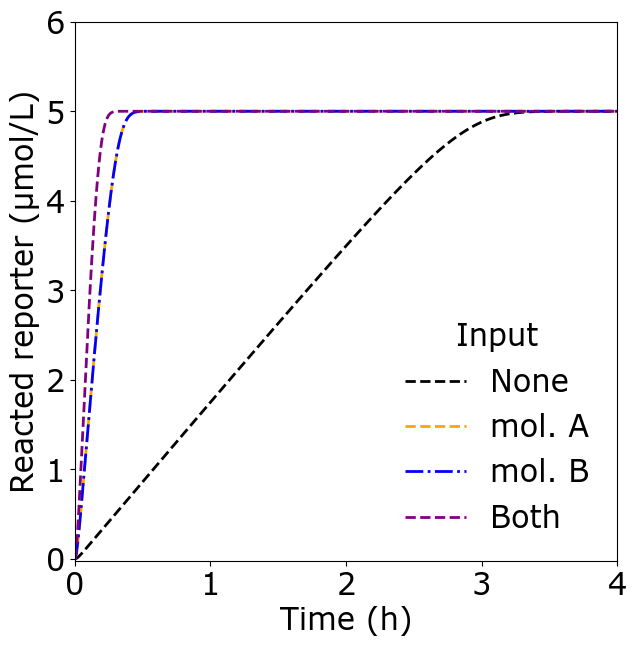

In [4]:
# Simulate
try:
    # Input templates
    A_conc = [0,1,0,1]
    B_conc = [0,0,1,1]

    idx_conditions = {'None':['black', '--'],
                      'mol. A': ['orange','--'],
                      'mol. B': ['blue','-.'],
                      'Both': ['purple','--']}

    for Ac, Bc, key in zip(A_conc, B_conc, idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_repA_repressible_assembly': 50, 'dna_repB_repressible_assembly': 50,
                                      'dna_Gate_1_2':10*1000, 'dna_Gate_3_2':10*1000, 
                                      'dna_Reporter_2':5*1000,
                                      'protein_repA':2500,'protein_repB':5000,
                                      'small_molecule_A': Ac*30000, 'small_molecule_B': Bc*20000, 
                                      }
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_txTMSEor.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                            initial_condition_dict = initial_concentration_dict)
        
        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['dna_Signal_2']/1000, label = key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])

    FormatPlot(ylabel='Reacted reporter (μmol/L)',ymax = 6, fig_name= 'Figure2_TFbiosensors')    
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

# Computing environment

In [5]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

